<a href="https://colab.research.google.com/github/anupbagale/python-for-ai-ml/blob/main/14-trees-and-ensembles/01_lesson.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 14: Trees and Ensembles

On tables of data (customers, patients, houses, transactions), the models that win most often in practice aren't neural networks. They're **ensembles of decision trees**: random forests and gradient boosting. They need little preparation of the data, handle mixed feature types and odd distributions, find interactions on their own, and are often the most accurate option available. In Module 12 a gradient boosting model, untuned, beat every linear model we built on the California housing data. This module explains how.

It starts with a single tree, which is easy to understand and easy to break, and shows the two ideas that turn weak, unstable trees into strong models: **averaging** many of them (bagging and random forests) and **correcting** them one after another (boosting).

**Contents**

1. A tree is a set of questions
2. How a tree chooses a question
3. Growing, stopping and pruning
4. Regression trees
5. Trees are unstable
6. Bagging: averaging away the variance
7. Random forests
8. Which features matter? Importance done right
9. Boosting: learning from mistakes
10. Gradient boosting in practice
11. What trees can't do
12. Choosing a model for tabular data

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn

DATA_URL = "https://raw.githubusercontent.com/anupbagale/python-for-ai-ml/main/05-files-and-data/data/penguins.csv"
local = Path("data/penguins.csv")
penguins = pd.read_csv(local if local.exists() else DATA_URL).dropna(subset=["bill_length_mm", "bill_depth_mm"])
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Categorical colours, always used in this order. The first three are checked to stay
# distinguishable for the common forms of colour blindness, even in scatter plots.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

SURFACE = "#fcfcfb"     # chart background
INK = "#0b0b0b"         # titles and important text
INK_2 = "#52514e"       # labels and tick text
MUTED = "#898781"       # de-emphasised marks
GRID = "#e1e0d9"        # gridlines
AXIS = "#c3c2b7"        # axis lines

# Sequential: one hue, light to dark, for magnitude (heatmaps, counts)
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "course_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
# Diverging: two opposite hues with a neutral grey in the middle, for values around zero
DIVERGING = LinearSegmentedColormap.from_list(
    "course_diverging", ["#184f95", "#86b6ef", "#f0efec", "#f0a3a2", "#c23a3a"])


def use_course_style():
    for cmap in (SEQUENTIAL, DIVERGING):
        if cmap.name not in mpl.colormaps:
            mpl.colormaps.register(cmap)
    mpl.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "figure.figsize": (7, 4),
        "font.size": 10,
        "text.color": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "grid.linestyle": "-",
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "axes.prop_cycle": mpl.cycler(color=PALETTE),
        "lines.linewidth": 1.6,
        "lines.solid_capstyle": "round",
        "lines.markersize": 6,
        "patch.linewidth": 0,
        "legend.frameon": False,
        "legend.labelcolor": INK_2,
        "image.cmap": "course_blues",
    })


use_course_style()

## 1. A tree is a set of questions

A **decision tree** predicts by asking a series of yes/no questions about the features, each one depending on the answer to the last. It's the same idea as the game of twenty questions, or a flowchart a doctor might follow. Here's a small tree that tells penguin species apart from two bill measurements:

In [3]:
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

X_peng = penguins[["bill_length_mm", "bill_depth_mm"]]
y_peng = penguins["species"]
small_tree = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X_peng, y_peng)
print(export_text(small_tree, feature_names=list(X_peng.columns)))

|--- bill_length_mm <= 42.35
|   |--- bill_depth_mm <= 15.10
|   |   |--- class: Gentoo
|   |--- bill_depth_mm >  15.10
|   |   |--- class: Adelie
|--- bill_length_mm >  42.35
|   |--- bill_depth_mm <= 16.35
|   |   |--- class: Gentoo
|   |--- bill_depth_mm >  16.35
|   |   |--- class: Chinstrap



Read it from the top. The first question is about bill length. Penguins with short bills go left, and a second question about bill depth separates most Adelies from the rest. Penguins with long bills go right, where bill depth separates Chinstraps (deep bills) from Gentoos (shallow bills). Each final box is a **leaf**, and its prediction is the most common species among the training penguins that ended up there.

`plot_tree` draws the same tree, with more detail in each box:

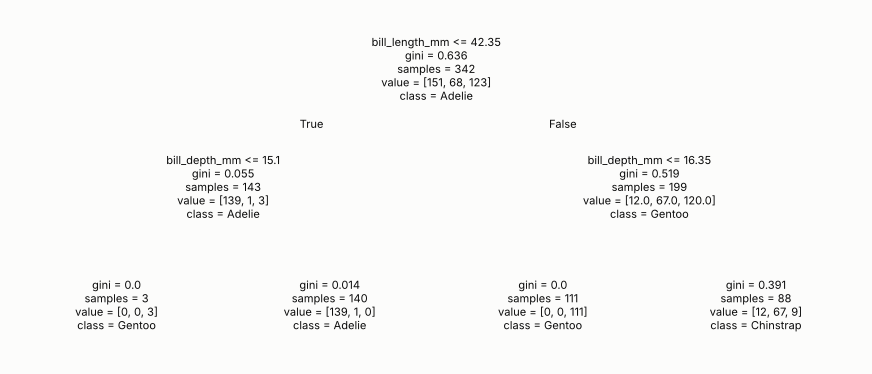

In [4]:
fig, ax = plt.subplots(figsize=(11, 4.6))
plot_tree(small_tree, feature_names=list(X_peng.columns), class_names=list(small_tree.classes_),
          impurity=True, proportion=False, rounded=True, fontsize=8, ax=ax)
plt.show()

Each box shows the question, the **gini** impurity (explained in the next section), the number of training penguins that reached it (`samples`), how many of each species they include (`value`), and the majority species (`class`).

Because every question compares **one feature** with a threshold, the tree cuts the feature space into **rectangles**, with one prediction in each:

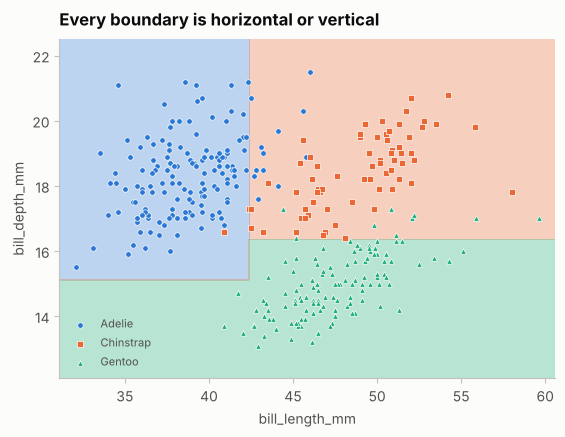

In [5]:
def plot_regions(model, X, y, ax, title, resolution=300):
    """Colour the plane by the model's prediction, and draw the training points on top."""
    classes = sorted(pd.unique(y))
    x0 = np.linspace(X.iloc[:, 0].min() - 1, X.iloc[:, 0].max() + 1, resolution)
    x1 = np.linspace(X.iloc[:, 1].min() - 1, X.iloc[:, 1].max() + 1, resolution)
    g0, g1 = np.meshgrid(x0, x1)
    grid = pd.DataFrame({X.columns[0]: g0.ravel(), X.columns[1]: g1.ravel()})
    codes = pd.Categorical(model.predict(grid), categories=classes).codes.reshape(g0.shape)
    ax.contourf(g0, g1, codes, levels=np.arange(len(classes) + 1) - 0.5, colors=PALETTE[:len(classes)], alpha=0.3)
    ax.grid(False)
    for i, (cls, marker) in enumerate(zip(classes, ["o", "s", "^"])):
        mask = np.asarray(y == cls)
        ax.scatter(X.iloc[mask, 0], X.iloc[mask, 1], color=PALETTE[i], marker=marker, s=16,
                   edgecolors=SURFACE, linewidths=0.5, label=str(cls))
    ax.set_xlabel(X.columns[0])
    ax.set_ylabel(X.columns[1])
    ax.set_title(title)


fig, ax = plt.subplots(figsize=(6.4, 4.4))
plot_regions(small_tree, X_peng, y_peng, ax, "Every boundary is horizontal or vertical")
ax.legend(loc="lower left", fontsize=8)
plt.show()

Three things make trees attractive:

- **They're easy to explain.** You can print the rules and follow them by hand, which matters when a decision needs justifying.
- **They need little preparation.** A question like "is income above 3.5?" works the same whatever the scale of the feature, so there's no need to standardise. Skewed features and outliers don't distort the splits, because only the **order** of the values matters.
- **They find interactions on their own.** The second question depends on the answer to the first, so the effect of bill depth can be different for short and long bills. A linear model would need an interaction feature for that (Module 12).

## 2. How a tree chooses a question

At each step, the tree tries **every feature** and **every threshold**, and picks the question that makes the two resulting groups as **pure** as possible: ideally, each group would contain only one class.

Purity is measured by an **impurity** function. The two common ones, for a group where the fraction of class `k` is `p_k`:

- **Gini impurity**: `1 - Σ p_k²`. It's the chance that two examples drawn at random from the group belong to different classes. 0 for a pure group.
- **Entropy**: `-Σ p_k log₂ p_k`, the information measure from Module 9. Also 0 for a pure group, and largest when the classes are evenly mixed.

In [6]:
def gini(labels):
    _, counts = np.unique(labels, return_counts=True)
    p = counts / counts.sum()
    return 1 - np.sum(p ** 2)


def entropy(labels):
    _, counts = np.unique(labels, return_counts=True)
    p = counts / counts.sum()
    return np.sum(p * np.log2(1 / p))       # the same as -Σ p log₂ p


for name, group in [("pure", ["A"] * 10), ("90/10", ["A"] * 9 + ["B"]), ("50/50", ["A"] * 5 + ["B"] * 5),
                    ("three equal", ["A", "B", "C"] * 4)]:
    print(f"{name:<12} gini {gini(group):.3f}   entropy {entropy(group):.3f}")

pure         gini 0.000   entropy 0.000
90/10        gini 0.180   entropy 0.469
50/50        gini 0.500   entropy 1.000
three equal  gini 0.667   entropy 1.585


A split's quality is the **weighted average** impurity of the two groups it creates, weighted by their sizes. Let's find the best first question about bill length by hand: try a threshold halfway between every pair of neighbouring values, and keep the one with the lowest weighted Gini.

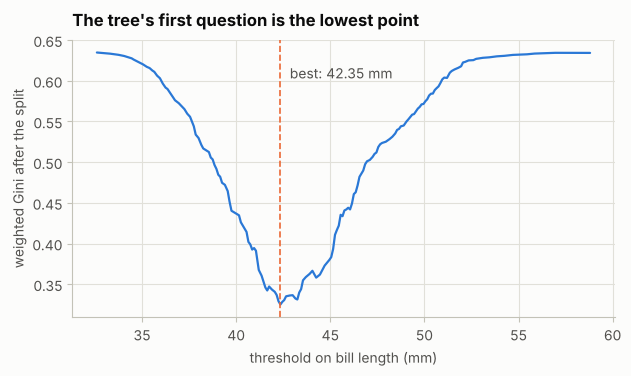

gini before splitting: 0.636
best threshold by hand: 42.35, weighted gini 0.325
scikit-learn's root threshold: 42.35


In [7]:
x = X_peng["bill_length_mm"].to_numpy()
labels = y_peng.to_numpy()
values = np.unique(x)
candidates = (values[:-1] + values[1:]) / 2       # halfway between neighbouring values

scores = []
for t in candidates:
    left, right = labels[x <= t], labels[x > t]
    scores.append((len(left) * gini(left) + len(right) * gini(right)) / len(labels))
best = candidates[int(np.argmin(scores))]

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(candidates, scores, color=PALETTE[0])
ax.axvline(best, color=PALETTE[1], linestyle="--", linewidth=1.2)
ax.text(best + 0.5, max(scores) * 0.95, f"best: {best:.2f} mm", color=INK_2)
ax.set_xlabel("threshold on bill length (mm)")
ax.set_ylabel("weighted Gini after the split")
ax.set_title("The tree's first question is the lowest point")
plt.show()
print(f"gini before splitting: {gini(labels):.3f}")
print(f"best threshold by hand: {best:.2f}, weighted gini {min(scores):.3f}")
print(f"scikit-learn's root threshold: {small_tree.tree_.threshold[0]:.2f}")

The same threshold scikit-learn chose. A real tree repeats this search for every feature and picks the overall winner, then repeats the whole thing inside each of the two groups, and so on. This strategy is **greedy**: it picks the best question **right now**, without looking ahead to see whether a worse question now would allow better ones later. Finding the truly best tree is far too slow, and greedy trees work well in practice.

Gini and entropy almost always choose the same splits. scikit-learn uses Gini by default (`criterion="gini"`), because it's slightly faster to compute.

## 3. Growing, stopping and pruning

If nothing stops it, a tree keeps splitting until every leaf is pure. On training data, that means it can reach 100% accuracy, even if the labels are noisy, by giving each awkward example a tiny leaf of its own. That's overfitting in its clearest form.

Here's a dataset where the two classes overlap (two interleaved half-moons with noise), and trees of three depths:

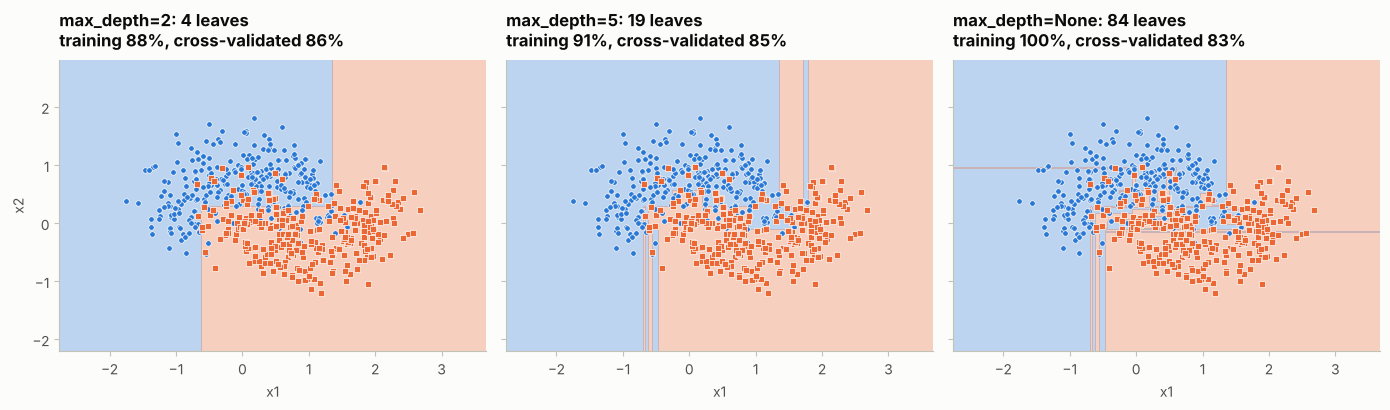

In [8]:
from sklearn.datasets import make_moons
from sklearn.model_selection import StratifiedKFold, cross_val_score

X_m, y_m = make_moons(n_samples=600, noise=0.35, random_state=0)
X_m = pd.DataFrame(X_m, columns=["x1", "x2"])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, depth in zip(axes, [2, 5, None]):
    tree = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(X_m, y_m)
    cv_acc = cross_val_score(DecisionTreeClassifier(max_depth=depth, random_state=0), X_m, y_m, cv=cv).mean()
    plot_regions(tree, X_m, pd.Series(y_m), ax,
                 f"max_depth={depth}: {tree.get_n_leaves()} leaves\ntraining {tree.score(X_m, y_m):.0%}, cross-validated {cv_acc:.0%}")
    if ax is not axes[0]:
        ax.set_ylabel("")
fig.tight_layout()
plt.show()

With depth 2, the tree is too simple: a few big rectangles miss the curve of the moons (high bias). With no limit, it carves out tiny islands around individual noisy points and scores 100% on the training data, but does worse on new data (high variance). The middle tree is about right.

The settings that stop a tree from growing too far are its most important hyperparameters:

| setting | what it does |
|---|---|
| `max_depth` | the maximum number of questions from the root to any leaf |
| `min_samples_leaf` | every leaf must contain at least this many training examples |
| `min_samples_split` | a node needs at least this many examples to be split |
| `max_leaf_nodes` | the maximum number of leaves in total |
| `ccp_alpha` | cost-complexity pruning: grow the full tree, then cut back branches that don't earn their keep |

`min_samples_leaf` is often the most useful: it stops the tree from making decisions based on one or two examples, whatever the depth. Here's cross-validated accuracy for a range of values of two settings:

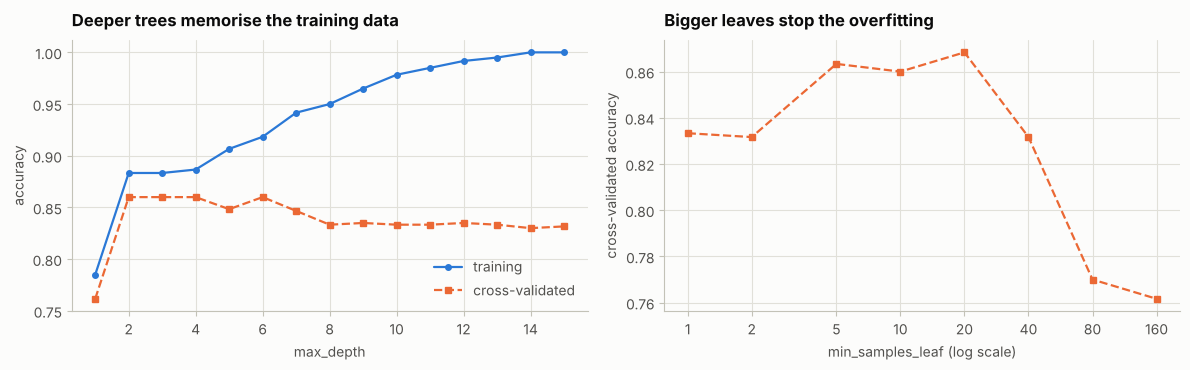

best depth 2: 0.860   best min_samples_leaf 20: 0.868


In [9]:
depths = range(1, 16)
leaf_sizes = [1, 2, 5, 10, 20, 40, 80, 160]
train_acc, cv_acc = [], []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=0)
    train_acc.append(tree.fit(X_m, y_m).score(X_m, y_m))
    cv_acc.append(cross_val_score(tree, X_m, y_m, cv=cv).mean())
leaf_cv = [cross_val_score(DecisionTreeClassifier(min_samples_leaf=m, random_state=0), X_m, y_m, cv=cv).mean() for m in leaf_sizes]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(depths, train_acc, color=PALETTE[0], marker="o", markersize=4, label="training")
axes[0].plot(depths, cv_acc, color=PALETTE[1], marker="s", markersize=4, linestyle="--", label="cross-validated")
axes[0].set_xlabel("max_depth")
axes[0].set_ylabel("accuracy")
axes[0].set_title("Deeper trees memorise the training data")
axes[0].legend(loc="lower right")
axes[1].plot(leaf_sizes, leaf_cv, color=PALETTE[1], marker="s", markersize=4, linestyle="--")
axes[1].set_xscale("log")
axes[1].set_xticks(leaf_sizes, [str(m) for m in leaf_sizes])
axes[1].minorticks_off()
axes[1].set_xlabel("min_samples_leaf (log scale)")
axes[1].set_ylabel("cross-validated accuracy")
axes[1].set_title("Bigger leaves stop the overfitting")
fig.tight_layout()
plt.show()
print(f"best depth {depths[int(np.argmax(cv_acc))]}: {max(cv_acc):.3f}   "
      f"best min_samples_leaf {leaf_sizes[int(np.argmax(leaf_cv))]}: {max(leaf_cv):.3f}")

On the left, training accuracy climbs to 100% as the tree deepens, while cross-validated accuracy peaks early and then falls: the classic overfitting picture from Module 12. On the right, requiring bigger leaves improves the full-depth tree substantially, until the leaves become so big that the tree is too coarse again.

## 4. Regression trees

For a numeric target, a tree works the same way, with two changes:

- A leaf predicts the **mean** of the training targets that reach it.
- Splits are chosen to minimise the **squared error** within the two groups (the weighted variance), instead of the Gini impurity.

The prediction is therefore a **step function**: flat within each region, jumping between regions. Here's a noisy curve and trees of three depths:

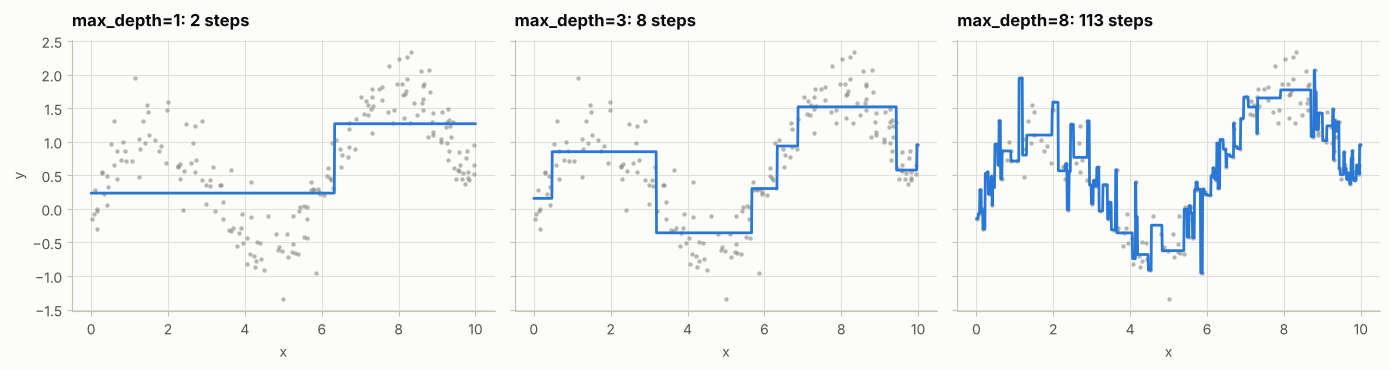

In [10]:
from sklearn.tree import DecisionTreeRegressor

rng = np.random.default_rng(0)
x_s = np.sort(rng.uniform(0, 10, 200))
y_s = np.sin(x_s) + 0.1 * x_s + rng.normal(0, 0.3, 200)
grid_s = np.linspace(0, 10, 1000)[:, None]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, depth in zip(axes, [1, 3, 8]):
    reg = DecisionTreeRegressor(max_depth=depth, random_state=0).fit(x_s[:, None], y_s)
    ax.scatter(x_s, y_s, s=10, color=MUTED, alpha=0.6)
    ax.plot(grid_s, reg.predict(grid_s), color=PALETTE[0], linewidth=2)
    ax.set_title(f"max_depth={depth}: {reg.get_n_leaves()} steps")
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
fig.tight_layout()
plt.show()

Depth 1 is a single step, called a **stump**. Depth 3 gives 8 steps that follow the general shape. Depth 8 follows every wiggle of the noise. Same trade-off as before, now visible as the shape of a curve.

## 5. Trees are unstable

Here's the biggest weakness of a single tree. Draw a slightly different training set from the same source, and a deep tree can change completely, because a different first question changes everything below it.

To see it, draw five **bootstrap samples** of the curve data (Module 9: sample the same number of points with replacement), fit a full-depth tree to each, and compare:

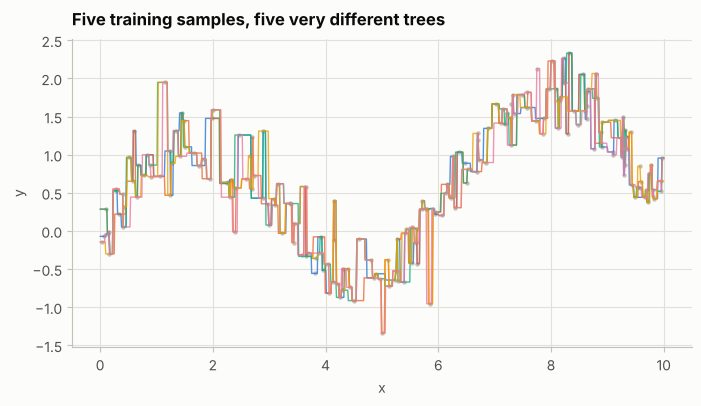

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(x_s, y_s, s=10, color=MUTED, alpha=0.5)
rng = np.random.default_rng(1)
for i in range(5):
    idx = rng.integers(0, len(x_s), len(x_s))
    reg = DecisionTreeRegressor(random_state=0).fit(x_s[idx, None], y_s[idx])
    ax.plot(grid_s, reg.predict(grid_s), color=PALETTE[i], linewidth=1, alpha=0.8)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Five training samples, five very different trees")
plt.show()

The five trees agree on the general shape but disagree wildly in the details: each has memorised its own sample's noise. In the language of Module 12, a deep tree has **low bias** (it can fit any shape) and **very high variance** (its predictions depend heavily on which data it happened to see).

Low bias and high variance: that's exactly the situation where **averaging** helps. If each tree's errors are partly random, averaging many trees cancels much of that randomness while keeping their shared, correct shape.

## 6. Bagging: averaging away the variance

**Bagging** (short for **b**ootstrap **agg**regat**ing**, invented by Leo Breiman in 1996) is that idea made into an algorithm:

1. Draw many bootstrap samples of the training data.
2. Fit a deep tree to each one.
3. Predict with the **average** of their predictions (for classification, average the probabilities or take a majority vote).

Here it is by hand, with 1, 10 and 200 trees:

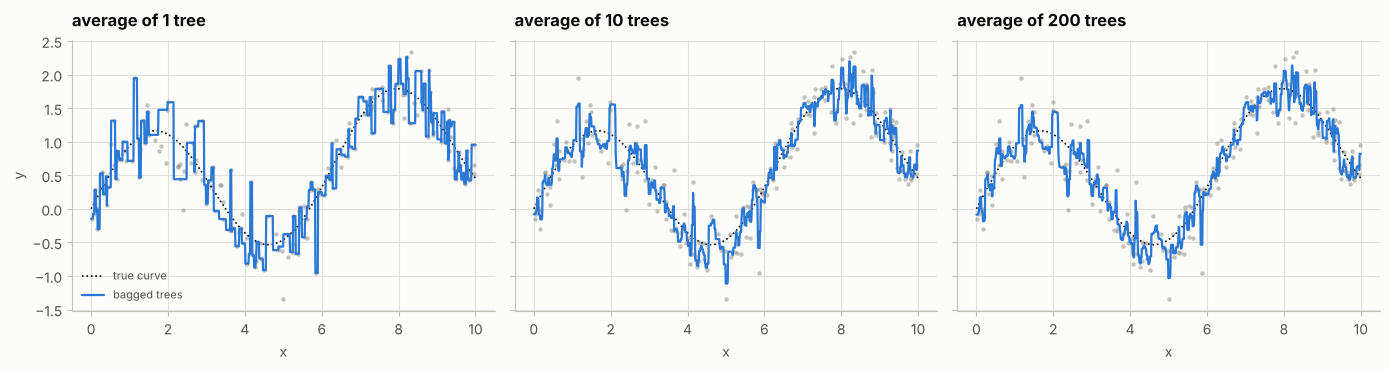

In [12]:
def bagged_predictions(x_train, y_train, x_new, n_trees, min_samples_leaf=1, seed=0):
    rng = np.random.default_rng(seed)
    total = np.zeros(len(x_new))
    for _ in range(n_trees):
        idx = rng.integers(0, len(x_train), len(x_train))
        tree = DecisionTreeRegressor(min_samples_leaf=min_samples_leaf, random_state=0)
        total += tree.fit(x_train[idx], y_train[idx]).predict(x_new)
    return total / n_trees


fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, n_trees in zip(axes, [1, 10, 200]):
    ax.scatter(x_s, y_s, s=10, color=MUTED, alpha=0.5)
    ax.plot(grid_s, np.sin(grid_s) + 0.1 * grid_s, color=INK, linestyle=":", linewidth=1.2, label="true curve")
    ax.plot(grid_s, bagged_predictions(x_s[:, None], y_s, grid_s, n_trees), color=PALETTE[0], linewidth=1.6, label="bagged trees")
    ax.set_title(f"average of {n_trees} tree{'s' if n_trees > 1 else ''}")
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

One tree is jagged. Ten trees are already much smoother. Two hundred trees give a curve that follows the true shape closely, even though every single tree in the average is badly overfitted.

To measure it, here's the error on fresh data from the same source, as the number of trees grows:

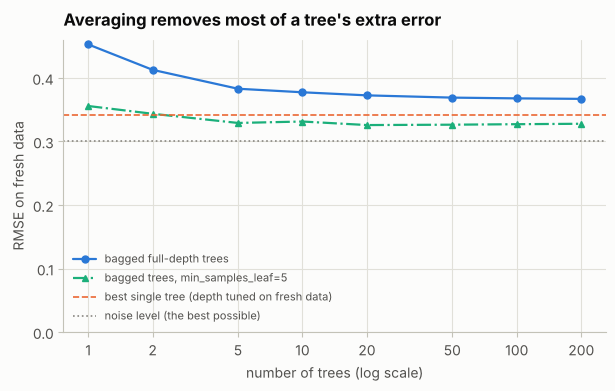

full-depth trees:      1 tree 0.453, 200 trees 0.367
min_samples_leaf=5:    1 tree 0.356, 200 trees 0.328
best single tree:      0.341


In [13]:
rng = np.random.default_rng(2)
x_fresh = rng.uniform(0, 10, 2000)
y_fresh = np.sin(x_fresh) + 0.1 * x_fresh + rng.normal(0, 0.3, 2000)

tree_counts = [1, 2, 5, 10, 20, 50, 100, 200]
def fresh_rmse(prediction):
    return np.sqrt(np.mean((y_fresh - prediction) ** 2))


bag_rmse = [fresh_rmse(bagged_predictions(x_s[:, None], y_s, x_fresh[:, None], n)) for n in tree_counts]
bag5_rmse = [fresh_rmse(bagged_predictions(x_s[:, None], y_s, x_fresh[:, None], n, min_samples_leaf=5)) for n in tree_counts]
best_tree_rmse = min(np.sqrt(np.mean((y_fresh - DecisionTreeRegressor(max_depth=d, random_state=0).fit(x_s[:, None], y_s).predict(x_fresh[:, None])) ** 2))
                     for d in range(1, 15))

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(tree_counts, bag_rmse, color=PALETTE[0], marker="o", markersize=5, label="bagged full-depth trees")
ax.plot(tree_counts, bag5_rmse, color=PALETTE[2], marker="^", markersize=5, linestyle="-.", label="bagged trees, min_samples_leaf=5")
ax.axhline(best_tree_rmse, color=PALETTE[1], linestyle="--", linewidth=1.2, label="best single tree (depth tuned on fresh data)")
ax.axhline(0.3, color=MUTED, linestyle=":", linewidth=1.2, label="noise level (the best possible)")
ax.set_xscale("log")
ax.set_xticks(tree_counts, [str(n) for n in tree_counts])
ax.minorticks_off()
ax.set_xlabel("number of trees (log scale)")
ax.set_ylabel("RMSE on fresh data")
ax.set_ylim(0, None)
ax.legend(loc="lower left", fontsize=8)
ax.set_title("Averaging removes most of a tree's extra error")
plt.show()
print(f"full-depth trees:      1 tree {bag_rmse[0]:.3f}, 200 trees {bag_rmse[-1]:.3f}")
print(f"min_samples_leaf=5:    1 tree {bag5_rmse[0]:.3f}, 200 trees {bag5_rmse[-1]:.3f}")
print(f"best single tree:      {best_tree_rmse:.3f}")

The error falls quickly with the first few trees, then levels off. Averaging full-depth trees removes most of the gap between one overfitted tree and the noise level, though in this simple one-feature example it doesn't quite reach the best single tree, whose depth was chosen by looking at the fresh data (an unfair advantage). Averaging trees that are only lightly restrained, with at least 5 examples per leaf, does beat it.

With many features, single trees are even more unstable, and the advantage of averaging is usually much larger. In the mini project, a forest beats the best single tree by about $9,000 of error.

Two useful facts about bagging:

- **More trees never cause overfitting.** Adding trees only makes the average more stable; the error levels off rather than rising. The cost of more trees is time and memory, not accuracy.
- **It comes with a free validation set.** Each bootstrap sample leaves out about 37% of the training examples (the chance that a given example is never drawn in `n` draws is `(1 - 1/n)ⁿ ≈ 1/e ≈ 0.37`). Those **out-of-bag** (OOB) examples weren't seen by that tree, so each training example can be predicted by the trees that didn't train on it. The OOB error is an honest estimate of the error on new data, with no need for cross-validation.

In [14]:
n = 1000
print(f"fraction never drawn in {n} draws: {(1 - 1 / n) ** n:.3f}   (1/e = {np.exp(-1):.3f})")

fraction never drawn in 1000 draws: 0.368   (1/e = 0.368)


## 7. Random forests

Averaging works best when the things being averaged make **different** mistakes. If all the trees made the same errors, averaging would change nothing. Bagged trees are less different than you might hope: if one feature is very strong, almost every tree uses it for its first question, and the trees end up similar.

A **random forest** (Breiman, 2001) adds one more source of randomness: at each split, the tree may only choose from a **random subset of the features**. Sometimes the strongest feature isn't on offer, so the tree has to find the next best question. The trees become more different from each other, and the average improves, even though each individual tree gets slightly worse.

The size of the subset is the `max_features` setting: all features gives plain bagging, `"sqrt"` (the square root of the number of features) is the usual choice for classification, and 1 makes every split's feature random. Here's the effect on the breast cancer data from Module 13:

In [15]:
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score
from sklearn.model_selection import train_test_split

cancer = load_breast_cancer(as_frame=True)
X_bc, y_bc = cancer.data, (cancer.target == 0).astype(int)
X_bc_train, X_bc_test, y_bc_train, y_bc_test = train_test_split(X_bc, y_bc, test_size=0.3, stratify=y_bc, random_state=0)

rows = {}
for label, max_features in [("all 30 features (bagging)", None), ("sqrt: 5 features", "sqrt"), ("1 feature", 1)]:
    forest = RandomForestClassifier(n_estimators=300, max_features=max_features, random_state=0, n_jobs=-1).fit(X_bc_train, y_bc_train)
    tree_probs = np.array([t.predict_proba(X_bc_test.to_numpy())[:, 1] for t in forest.estimators_])
    correlations = np.corrcoef(tree_probs)[np.triu_indices(len(tree_probs), k=1)]
    forest_probs = forest.predict_proba(X_bc_test)[:, 1]
    rows[label] = {
        "correlation between trees": correlations.mean(),
        "average single-tree accuracy": np.mean([accuracy_score(y_bc_test, p >= 0.5) for p in tree_probs]),
        "forest accuracy": accuracy_score(y_bc_test, forest_probs >= 0.5),
        "forest log loss": log_loss(y_bc_test, forest_probs),
    }
pd.DataFrame(rows).T.round(3)

,correlation between trees,average single-tree accuracy,forest accuracy,forest log loss
all 30 features (bagging),0.822,0.910,0.936,0.353
sqrt: 5 features,0.797,0.909,0.942,0.334
1 feature,0.702,0.885,0.953,0.169


Reading across the rows, as the trees get fewer features to choose from:

- the trees become **less correlated** with each other
- each **single tree gets a little worse**, since it's often denied the best question
- the **forest gets better**, because its trees' mistakes overlap less and cancel more

That's the central trade-off of random forests. (With only 171 test tumours, the accuracy differences amount to a few tumours each, so treat this table as an illustration of the pattern rather than a precise measurement. The log loss of plain bagging is also inflated by a few confident mistakes.) In practice, the defaults are good: `max_features="sqrt"` for classification, and for regression, scikit-learn's default of all features (`1.0`) is often beaten by a fraction such as 0.33 to 0.5. It's one of the few settings worth tuning.

Random forests are popular for good reasons. They work well with almost no tuning, rarely overfit badly, give an OOB estimate for free, and train in parallel (`n_jobs=-1` uses every processor core).

## 8. Which features matter? Importance done right

People always want to know which features a model relies on. Tree ensembles offer two very different answers, and one of them is often misleading.

**Impurity-based importance** (`feature_importances_`) adds up how much each feature reduced the impurity across all the splits that used it. It's free, since it's computed during training. But it's measured on the **training data**, so a feature that the trees used to memorise noise gets credit too.

**Permutation importance** shuffles one feature's values on **held-out data**, breaking its link with the target, and measures how much worse the model gets. If the model doesn't really need the feature, shuffling it does no harm.

To compare them fairly, we need data where we **know** the truth. Here's a made-up health dataset: the risk of a condition depends on smoking (a strong effect), exercise level and age (weaker effects), and the last column is pure random noise:

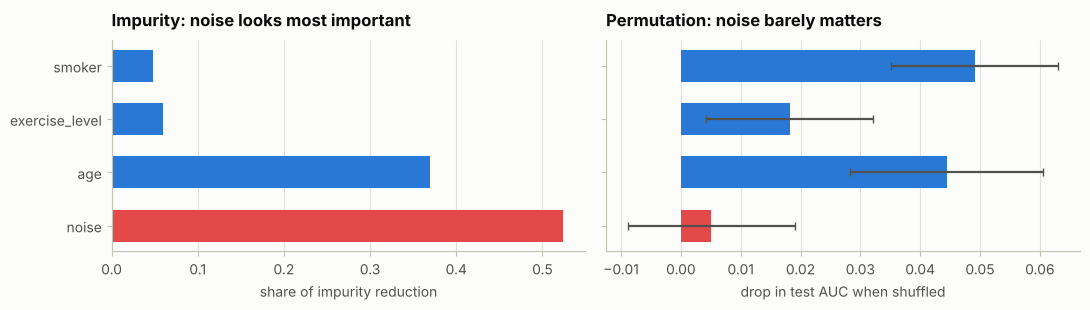

,impurity (training data),permutation (test data),permutation spread (std)
smoker,0.0477,0.0491,0.0140
exercise_level,0.0592,0.0182,0.0140
age,0.3693,0.0444,0.0161
noise,0.5238,0.0051,0.0140


In [16]:
from sklearn.inspection import permutation_importance

rng = np.random.default_rng(0)
n = 2000
health = pd.DataFrame({
    "smoker": rng.integers(0, 2, n),                 # 0 or 1
    "exercise_level": rng.integers(0, 3, n),         # 0, 1 or 2
    "age": rng.uniform(20, 80, n).round(),
    "noise": rng.normal(size=n),                     # unrelated to the outcome
})
log_odds = -1.5 + 1.2 * health["smoker"] - 0.5 * health["exercise_level"] + 0.03 * (health["age"] - 50)
condition = (rng.random(n) < 1 / (1 + np.exp(-log_odds))).astype(int)
H_train, H_test, c_train, c_test = train_test_split(health, condition, test_size=0.5, random_state=0)

forest_h = RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1).fit(H_train, c_train)
perm = permutation_importance(forest_h, H_test, c_test, n_repeats=20, random_state=0, scoring="roc_auc")
importances = pd.DataFrame({"impurity (training data)": forest_h.feature_importances_,
                            "permutation (test data)": perm.importances_mean,
                            "permutation spread (std)": perm.importances_std}, index=health.columns)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
order = ["smoker", "exercise_level", "age", "noise"][::-1]
axes[0].barh(order, importances.loc[order, "impurity (training data)"], color=[PALETTE[7] if f == "noise" else PALETTE[0] for f in order], height=0.6)
axes[0].set_title("Impurity: noise looks most important")
axes[0].set_xlabel("share of impurity reduction")
axes[1].barh(order, importances.loc[order, "permutation (test data)"], xerr=importances.loc[order, "permutation spread (std)"],
             color=[PALETTE[7] if f == "noise" else PALETTE[0] for f in order], height=0.6, error_kw={"ecolor": INK_2, "capsize": 3})
axes[1].set_title("Permutation: noise barely matters")
axes[1].set_xlabel("drop in test AUC when shuffled")
for ax in axes:
    ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()
importances.round(4)

The impurity importance ranks the **pure noise** column as the most important feature, ahead of smoking, the strongest real effect. The reason: fully grown trees keep splitting until their leaves are pure, and a continuous feature with 1,000 different values offers endless thresholds for carving the training data into tiny groups. `smoker` has only one possible threshold, so once it's used it has nothing more to offer. Impurity importance is **biased towards features with many distinct values**, and it rewards memorisation.

Permutation importance on the test data gets it right: smoking matters most, and shuffling the noise column changes almost nothing (its bar is about the size of its own error bar).

Rules for importance:

- **Use permutation importance on held-out data.** scikit-learn's `permutation_importance` works with any model, not just trees.
- **Correlated features share their importance.** If two features carry the same information, shuffling one does little harm because the model can use the other, so both can look unimportant. Group related features or check them together.
- **Importance is about the model, not the world.** It says what this model relies on, which isn't the same as what causes the outcome. A feature can be important because it's a proxy for something else, or because of leakage.

To see **how** a feature affects predictions, not just how much, use a **partial dependence plot**: set the feature to each value in a range for every example, and average the model's predictions. You'll use them in the mini project.

You'll also hear a lot about **SHAP values** (from a 2017 paper by Scott Lundberg and Su-In Lee). They split each individual prediction into a contribution from every feature, so that the contributions add up to the prediction, using an idea from game theory for sharing out a reward fairly. They're popular for explaining single decisions ("why was this loan refused?") and have a fast exact method for tree ensembles, in the `shap` library (`pip install shap`). The same cautions apply: they describe the model, and correlated features make the split between them partly arbitrary.

## 9. Boosting: learning from mistakes

Bagging fits many trees **independently** and averages them, which cures variance. **Boosting** takes the opposite approach: it fits trees **one after another**, each one trying to correct the mistakes of all the trees before it. It starts from simple, **shallow** trees with high bias, and reduces the bias step by step.

For regression with squared error, **gradient boosting** is simple to write down:

1. Start with a constant prediction: the mean of the targets.
2. Compute the **residuals**: the target minus the current prediction. These are the mistakes so far.
3. Fit a small tree to the residuals, so it learns where the predictions are too high or too low.
4. Add a fraction of that tree's predictions to the current prediction. The fraction is the **learning rate**.
5. Repeat from step 2.

Here it is by hand, on the curve data:

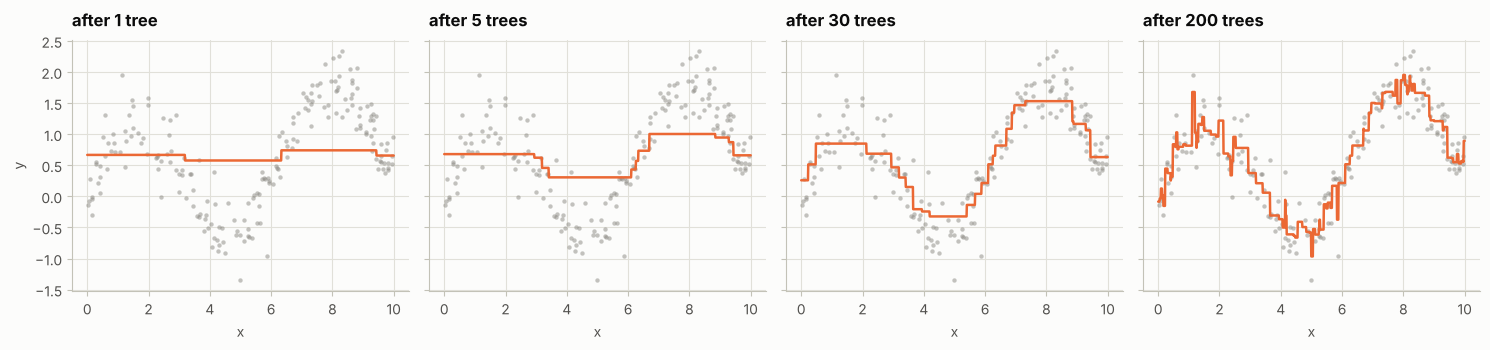

In [17]:
def boost_by_hand(x_train, y_train, x_new, n_trees, learning_rate=0.1, max_depth=2):
    prediction_train = np.full(len(y_train), y_train.mean())
    prediction_new = np.full(len(x_new), y_train.mean())
    for _ in range(n_trees):
        residuals = y_train - prediction_train
        tree = DecisionTreeRegressor(max_depth=max_depth, random_state=0).fit(x_train, residuals)
        prediction_train += learning_rate * tree.predict(x_train)
        prediction_new += learning_rate * tree.predict(x_new)
    return prediction_new


fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for ax, n_trees in zip(axes, [1, 5, 30, 200]):
    ax.scatter(x_s, y_s, s=10, color=MUTED, alpha=0.5)
    ax.plot(grid_s, boost_by_hand(x_s[:, None], y_s, grid_s, n_trees), color=PALETTE[1], linewidth=1.8)
    ax.set_title(f"after {n_trees} tree{'s' if n_trees > 1 else ''}")
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
fig.tight_layout()
plt.show()

After one tree (of depth 2, with a learning rate of 0.1), the prediction has barely moved from the flat mean. Each new tree nudges it towards the data where the mistakes are largest. After 30 trees the general shape is there; after 200 it follows the curve closely.

Why "gradient"? For squared error, the residual `y - F(x)` is the negative **gradient** of the loss with respect to the prediction. So each tree takes a step of gradient descent (Module 9), but in the space of functions instead of the space of weights. For other losses, such as log loss for classification, the trees are fitted to that loss's negative gradient instead. That's what makes gradient boosting work for almost any loss you can differentiate.

### The learning rate and the number of trees

These two settings work together. A smaller learning rate means each tree corrects less, so more trees are needed, but the end result is usually better, because many small steps follow the data more carefully than a few big ones. Unlike bagging, boosting **can** overfit with too many trees: it keeps correcting, and eventually it's correcting the noise.

scikit-learn's `GradientBoostingRegressor` implements the same algorithm, and `staged_predict` gives the prediction after each tree, so we can watch the error on fresh data:

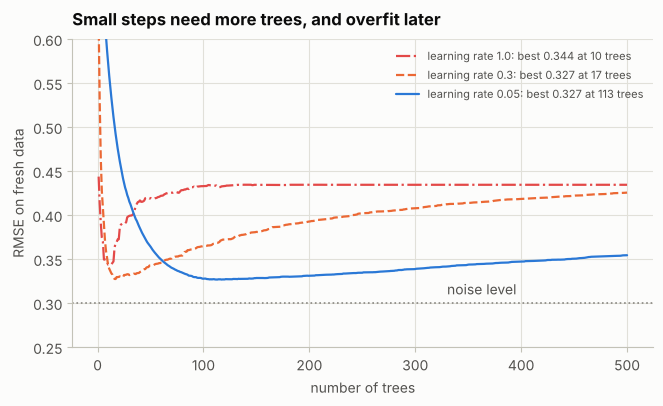

by hand vs scikit-learn, 200 trees: RMSE 0.3469 vs 0.3469


In [18]:
from sklearn.ensemble import GradientBoostingRegressor

fig, ax = plt.subplots(figsize=(7.5, 4))
for (rate, colour, style) in [(1.0, PALETTE[7], "-."), (0.3, PALETTE[1], "--"), (0.05, PALETTE[0], "-")]:
    gbr = GradientBoostingRegressor(n_estimators=500, learning_rate=rate, max_depth=2, random_state=0).fit(x_s[:, None], y_s)
    errors = [np.sqrt(np.mean((y_fresh - p) ** 2)) for p in gbr.staged_predict(x_fresh[:, None])]
    best_n = int(np.argmin(errors)) + 1
    ax.plot(range(1, 501), errors, color=colour, linestyle=style, label=f"learning rate {rate}: best {min(errors):.3f} at {best_n} trees")
ax.axhline(0.3, color=MUTED, linestyle=":", linewidth=1.2)
ax.text(330, 0.31, "noise level", color=INK_2)
ax.set_xlabel("number of trees")
ax.set_ylabel("RMSE on fresh data")
ax.set_ylim(0.25, 0.6)
ax.legend(loc="upper right", fontsize=8)
ax.set_title("Small steps need more trees, and overfit later")
plt.show()

hand = boost_by_hand(x_s[:, None], y_s, x_fresh[:, None], 200, learning_rate=0.1, max_depth=2)
library = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=2, random_state=0).fit(x_s[:, None], y_s).predict(x_fresh[:, None])
print(f"by hand vs scikit-learn, 200 trees: RMSE {np.sqrt(np.mean((y_fresh - hand) ** 2)):.4f} vs {np.sqrt(np.mean((y_fresh - library) ** 2)):.4f}")

With a learning rate of 1.0, each tree fully corrects the previous mistakes: the error drops fastest, bottoms out early, and then climbs as the model starts fitting noise. With 0.05, progress is slow and steady. It reaches the same best error as 0.3, but the error stays close to that best value over a much wider range of tree counts, so the exact number of trees matters far less.

So the practical recipe is: pick a fairly small learning rate (0.05 to 0.1), and choose the number of trees by watching a validation set, stopping when it stops improving. This is called **early stopping**, and the next section shows it built in.

(Our hand-written version and scikit-learn's give almost the same error. They're not identical because scikit-learn's trees use a slightly different split criterion, called Friedman's MSE.)

## 10. Gradient boosting in practice

`GradientBoostingRegressor` and `GradientBoostingClassifier` are fine for small data, but slow for large data, because every split searches every value of every feature. Modern boosting libraries use a trick: **histograms**. Each feature is first sorted into at most 255 bins, and splits are only considered between bins. That makes training many times faster, with almost no loss of accuracy.

scikit-learn's version is `HistGradientBoostingRegressor` and `HistGradientBoostingClassifier`. They also:

- handle **missing values** natively: at each split, the tree learns which side missing values should go to
- support **categorical features** directly, with `categorical_features` (as in Module 13's mini project)
- have **early stopping** built in: with `early_stopping=True` (automatic for more than 10,000 rows), they set aside a validation fraction and stop when it hasn't improved for `n_iter_no_change` rounds

Here's the speed difference on a larger synthetic dataset, and missing values handled without any imputation:

In [19]:
import time

from sklearn.datasets import make_regression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error

X_big, y_big = make_regression(n_samples=50_000, n_features=20, n_informative=10, noise=10, random_state=0)
X_big_train, X_big_test, y_big_train, y_big_test = train_test_split(X_big, y_big, test_size=0.2, random_state=0)

for name, model in [("GradientBoostingRegressor", GradientBoostingRegressor(n_estimators=100, random_state=0)),
                    ("HistGradientBoostingRegressor", HistGradientBoostingRegressor(max_iter=100, early_stopping=False, random_state=0))]:
    start = time.perf_counter()
    model.fit(X_big_train, y_big_train)
    seconds = time.perf_counter() - start
    rmse = np.sqrt(mean_squared_error(y_big_test, model.predict(X_big_test)))
    print(f"{name:<30} {seconds:5.1f} seconds   test RMSE {rmse:.1f}")

X_missing = X_big_train.copy()
X_missing[rng.random(X_missing.shape) < 0.2] = np.nan        # blank out 20% of all values
hgb_missing = HistGradientBoostingRegressor(random_state=0).fit(X_missing, y_big_train)
print(f"with 20% of training values missing, no imputation: test RMSE {np.sqrt(mean_squared_error(y_big_test, hgb_missing.predict(X_big_test))):.1f}")

GradientBoostingRegressor       36.0 seconds   test RMSE 51.1


HistGradientBoostingRegressor    0.8 seconds   test RMSE 30.0


with 20% of training values missing, no imputation: test RMSE 36.7


Many times faster. (Your exact timings will differ.) The histogram model is also more accurate here, but that's mostly because of different defaults rather than the histograms: its trees have up to 31 leaves, while `GradientBoostingRegressor` uses trees of depth 3, with at most 8 leaves, and this dataset rewards bigger trees. With a fifth of the training values blanked out, the model still trains without complaint and loses some accuracy, which is what you'd expect from having less information.

### The wider family

Three open-source libraries made histogram-based boosting famous, and you'll meet them in practice and in competitions:

- **XGBoost** (2014), which popularised gradient boosting with regularisation and efficient engineering
- **LightGBM** (2017, from Microsoft), which introduced many of the speed tricks scikit-learn's version uses
- **CatBoost** (2017, from Yandex), with particularly careful handling of categorical features

They all follow the ideas in this module, have scikit-learn-style interfaces, and install with `pip`. scikit-learn's own `HistGradientBoosting` models are close to LightGBM in design and are a good default that needs nothing extra installed.

### The settings that matter

For any gradient boosting library, roughly in order of importance:

| setting (scikit-learn name) | what it does | typical starting point |
|---|---|---|
| `learning_rate` | size of each correction | 0.05 to 0.1 |
| `max_iter` (number of trees) | choose by early stopping | large, with early stopping |
| `max_leaf_nodes` or `max_depth` | size of each tree, and so how many features can interact | 15 to 63 leaves, or depth 3 to 8 |
| `min_samples_leaf` | smallest leaf allowed | 20 (the default); more for noisy data |
| `l2_regularization` | shrinks leaf values | 0, then try 0.1 to 10 |

## 11. What trees can't do

Every model family has blind spots. Trees have two important ones.

**They can't extrapolate.** A tree's prediction is the average of training targets in a leaf, so it can never predict a value outside the range it saw in training. Beyond the edge of the training data, the prediction simply stays flat. A linear model continues the trend, which can be right or badly wrong, but a tree can't even try:

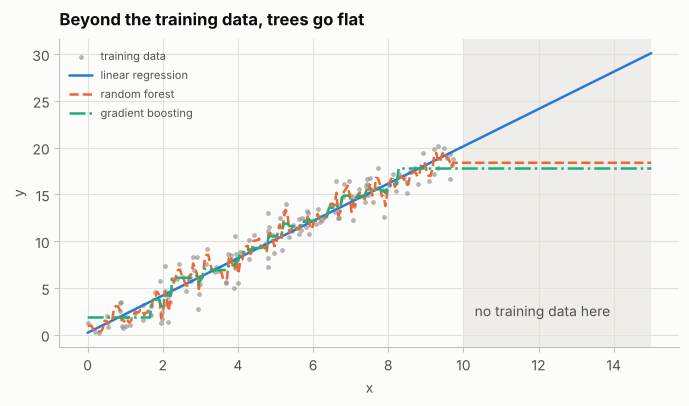

In [20]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

rng = np.random.default_rng(3)
x_trend = rng.uniform(0, 10, 150)
y_trend = 2 * x_trend + rng.normal(0, 1.5, 150)
grid_wide = np.linspace(0, 15, 300)[:, None]

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(x_trend, y_trend, s=12, color=MUTED, alpha=0.6, label="training data")
ax.axvspan(10, 15, color=GRID, alpha=0.5)
ax.text(10.3, 2, "no training data here", color=INK_2)
for (name, model), colour, style in zip({"linear regression": LinearRegression(),
                                          "random forest": RandomForestRegressor(n_estimators=200, random_state=0),
                                          "gradient boosting": HistGradientBoostingRegressor(random_state=0)}.items(),
                                         PALETTE, ["-", "--", "-."]):
    ax.plot(grid_wide, model.fit(x_trend[:, None], y_trend).predict(grid_wide), color=colour, linestyle=style, linewidth=1.8, label=name)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend(loc="upper left", fontsize=8)
ax.set_title("Beyond the training data, trees go flat")
plt.show()

This matters whenever new data can fall outside the training range: prices that keep rising over time, a sensor reading beyond anything seen before, the economy entering a new state. You saw it in Module 13's mini project: gradient boosting's probabilities were far too low on the future calls, because interest rates had fallen below anything in its training data.

**Smooth and diagonal patterns need many splits.** A tree approximates a straight line with a staircase, and a diagonal boundary with many small rectangles. With enough data and enough trees, ensembles get close, but a linear model would capture the same pattern exactly with a couple of numbers. On small datasets with mostly linear effects, a linear model can win.

A third limit: trees work with the **features you give them**, one at a time. They're poor at discovering that a ratio or difference of two features is what matters, so feature engineering (Module 12) still helps them, just less than it helps linear models.

## 12. Choosing a model for tabular data

A rough guide, from the experience of many practitioners and benchmarks:

| | linear models | random forests | gradient boosting |
|---|---|---|---|
| accuracy on typical tables | good with good features | very good | often the best |
| tuning needed | little | very little | some (learning rate, trees, size) |
| feature preparation | a lot: scaling, logs, interactions | very little | very little |
| extrapolation | continues the trend | flat | flat |
| explaining the model | read the weights | importance, partial dependence | importance, partial dependence |
| speed on large data | very fast | moderate, parallel | fast (histogram versions) |

What about neural networks? On images, sound and text they're unbeatable (Part 3). On ordinary tables they usually aren't: a well-known 2022 study by Léo Grinsztajn, Edouard Oyallon and Gaël Varoquaux compared them on 45 tabular datasets and found tree ensembles still came out ahead on medium-sized data, while being much cheaper to train. Part of the reason is the properties above: tables have features with different meanings and scales, irregular patterns and uninformative columns, and trees cope with all of those naturally.

A dependable order of work for a new tabular problem:

1. A **baseline** (mean or majority class).
2. A **linear model** with sensible features: a reference point, and sometimes good enough.
3. A **random forest** with default settings: strong, quick to set up, hard to get badly wrong.
4. **Gradient boosting** with early stopping, then tune the learning rate, tree size and leaf size with cross-validation.
5. Compare them honestly (Module 13), with the kind of validation that matches how the model will be used, and choose by accuracy **and** by what the situation needs: speed, simplicity or explanations.

## Summary

- A **decision tree** asks a sequence of yes/no questions, each comparing one feature with a threshold. It splits the feature space into rectangles and predicts the majority class (or the mean) in each.
- Splits are chosen **greedily** to minimise **impurity**: Gini or entropy for classes, squared error for numbers. Trees need no scaling and find interactions on their own.
- Deep trees **overfit**; control them with `max_depth`, `min_samples_leaf`, `max_leaf_nodes` or `ccp_alpha`.
- Single trees are **unstable** (high variance). **Bagging** averages trees fitted to bootstrap samples, which removes much of the variance; more trees never hurt. **Out-of-bag** examples give a free validation estimate.
- **Random forests** also limit each split to a random subset of features (`max_features`), making trees less correlated so the average works better.
- **Impurity importance** is biased towards features with many values and can rank noise highly. Use **permutation importance** on held-out data, and remember that importance describes the model, not causes.
- **Gradient boosting** fits small trees one after another to the current mistakes (the negative gradient of the loss). A small **learning rate** with many trees and **early stopping** works best. Boosting can overfit with too many trees.
- **Histogram-based boosting** (`HistGradientBoosting`, LightGBM, XGBoost, CatBoost) is fast, handles missing values and categories, and is often the most accurate choice for tabular data.
- Trees **can't extrapolate** beyond the training range, and approximate smooth or diagonal patterns with steps.

Next, open `02_exercises.ipynb`.